# 02 · E2 — Stokastik sentetik deney (makale Şekil 1, sağ · Teorem 3)
**Sorumlu:** Anıl · **Plan adımı:** A3.1

**Problem:** her adımda bağımsız olarak $0.01$ olasılıkla $1010x$, aksi halde $-10x$. Beklenen gradyan $0.01\cdot1010-0.99\cdot10=0.2>0$ ⇒ optimum $x^*=-1$.

**Çıktılar:** `results/e2_synthetic_stochastic/*.csv`, `figures/e2.*`

## Makaleden sapmalar
| Detay | Bizim seçimimiz | Gerekçe |
|---|---|---|
| α, takvim | E1'de AMSGrad için seçilen (aşağıda) | Makale vermiyor |
| Seed | 0–4 | Proje kuralı (final koşular 5 seed) |
| Rastgelelik | Aynı seed'de Adam ve AMSGrad **aynı** gradyan dizisini görür | Adil karşılaştırma |
| İterasyon | 10M | Uzun vadeli davranış |
| ε, bias correction | 0, yok | Makalenin analizi |

In [1]:
# --- Kurulum: repo'yu çek, yolları ayarla (00_tests ile aynı) ---
import os, sys, subprocess
REPO = "https://github.com/ybilgici/DeepLearning_Proje.git"
if os.path.exists("/kaggle"):
    ROOT = "/kaggle/working/DeepLearning_Proje"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", REPO, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
else:  # lokal çalıştırma: notebooks/ klasörünün bir üstü repo kökü
    ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import math
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from optim import paper_adam_step, init_state                     # Yiğit — ortak optimizer
from common.synthetic import (simulate, write_csv, online_grad, PeriodicGrad, StochasticGrad,
                              STYLE, style, band, save_fig)

QUICK = os.environ.get("QUICK", "0") == "1"   # True → kısa test koşusu (adım sayıları küçülür)
FIG = os.path.join(ROOT, "figures")
print("torch", torch.__version__, "| QUICK =", QUICK, "| commit:",
      subprocess.run(["git", "-C", ROOT, "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip())

torch 2.15.0+cu132 | QUICK = False | commit: d0b821c


## 1. Ayarlar — E1'den gelen α

In [2]:
BEST_LR, BEST_SCHED = 0.5, "sqrt"   # 01 notebook'undaki 'best' tablosunda AMSGrad + sqrt satırı
SEEDS = [0, 1, 2, 3, 4]
T = 100_000 if QUICK else 10_000_000
LOG = 1_000 if QUICK else 10_000
cfg = pd.DataFrame([dict(optimizer=o, lr=BEST_LR, schedule=BEST_SCHED, beta1=0.9, beta2=0.99, seed=s)
                    for o in ("adam", "amsgrad") for s in SEEDS])
cfg

,optimizer,lr,schedule,beta1,beta2,seed
0,adam,0.5,sqrt,0.9,0.99,0
1,adam,0.5,sqrt,0.9,0.99,1
2,adam,0.5,sqrt,0.9,0.99,2
3,adam,0.5,sqrt,0.9,0.99,3
4,adam,0.5,sqrt,0.9,0.99,4
5,amsgrad,0.5,sqrt,0.9,0.99,0
6,amsgrad,0.5,sqrt,0.9,0.99,1
7,amsgrad,0.5,sqrt,0.9,0.99,2
8,amsgrad,0.5,sqrt,0.9,0.99,3
9,amsgrad,0.5,sqrt,0.9,0.99,4


## 2. Koşu — 10 koşu tek tensörde

In [3]:
grad = StochasticGrad(seed_idx=cfg["seed"].values, n_seeds=len(SEEDS), p=0.01)
out = simulate(cfg, T, grad, x_star=-1.0, log_every=LOG)
print(f"süre: {out['seconds']:.0f} s")
write_csv("e2", cfg, out, os.path.join(ROOT, "results/e2_synthetic_stochastic"))
cfg.assign(final_x=out["x_final"], final_avg_regret=out["avg_regret_final"])

  t=  1,000,000  ( 186.7 s)


  t=  2,000,000  ( 366.5 s)


  t=  3,000,000  ( 539.5 s)


  t=  4,000,000  ( 701.2 s)


  t=  5,000,000  ( 819.7 s)


  t=  6,000,000  ( 938.6 s)


  t=  7,000,000  (1056.6 s)


  t=  8,000,000  (1177.7 s)


  t=  9,000,000  (1292.8 s)


  t= 10,000,000  (1409.4 s)
süre: 1409 s


,optimizer,lr,schedule,beta1,beta2,seed,final_x,final_avg_regret
0,adam,0.5,sqrt,0.9,0.99,0,0.988726,0.444196
1,adam,0.5,sqrt,0.9,0.99,1,0.998155,0.432148
2,adam,0.5,sqrt,0.9,0.99,2,0.997194,0.346155
3,adam,0.5,sqrt,0.9,0.99,3,1.000000,0.574465
4,adam,0.5,sqrt,0.9,0.99,4,0.995026,0.510402
5,amsgrad,0.5,sqrt,0.9,0.99,0,-1.000000,0.066232
6,amsgrad,0.5,sqrt,0.9,0.99,1,-0.992788,0.025426
7,amsgrad,0.5,sqrt,0.9,0.99,2,-0.992491,0.010272
8,amsgrad,0.5,sqrt,0.9,0.99,3,-0.994726,0.026330
9,amsgrad,0.5,sqrt,0.9,0.99,4,-0.993531,0.047499


## 3. Figür — ortalama ± std (5 seed)

kaydedildi: /home/claude/DeepLearning_Proje/figures/e2.png / .pdf


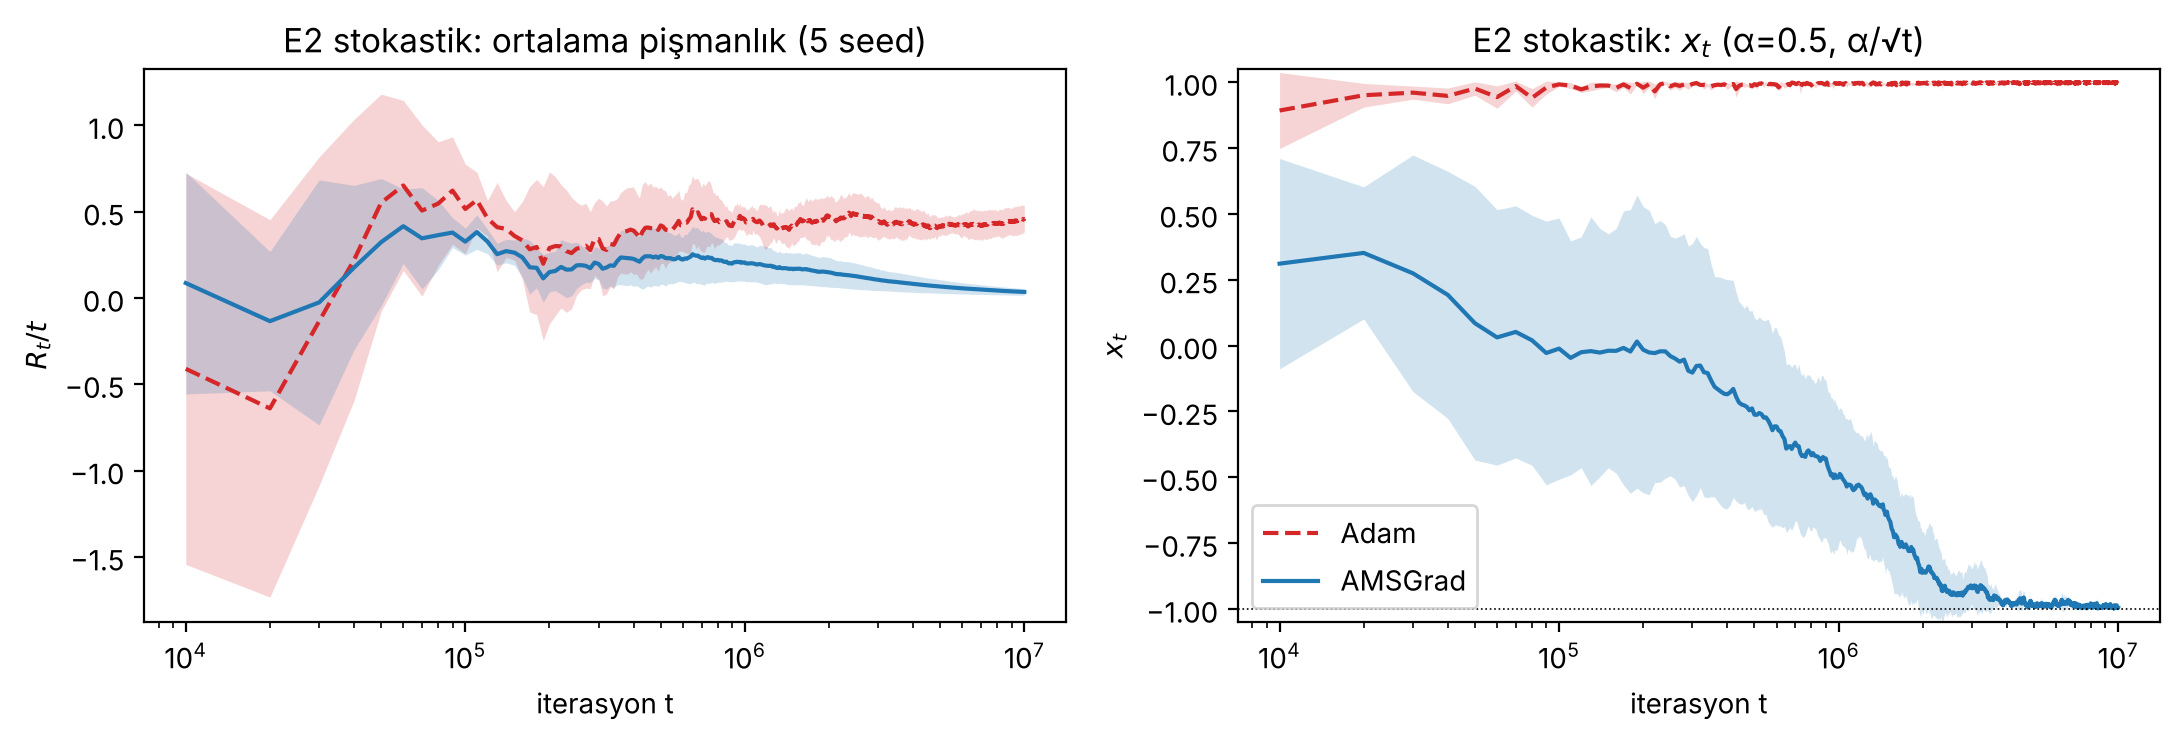

               mean       std
optimizer                    
adam       0.995820  0.004352
amsgrad   -0.994707  0.003082


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for o in ("adam", "amsgrad"):
    idx = cfg.index[cfg.optimizer == o]
    band(ax[0], out["steps"], out["avg_regret"][:, idx], o)
    band(ax[1], out["steps"], out["x"][:, idx], o)
tak = "α/√t" if BEST_SCHED == "sqrt" else "sabit α"
ax[0].set(xscale="log", xlabel="iterasyon t", ylabel="$R_t/t$", title="E2 stokastik: ortalama pişmanlık (5 seed)")
ax[1].set(xscale="log", xlabel="iterasyon t", ylabel="$x_t$", ylim=(-1.05, 1.05), title=f"E2 stokastik: $x_t$ (α={BEST_LR}, {tak})")
ax[1].axhline(-1, color="k", lw=0.6, ls=":"); ax[1].legend()
fig.tight_layout(); save_fig(fig, "e2", FIG); plt.show()

print(cfg.assign(final_x=out["x_final"]).groupby("optimizer")["final_x"].agg(["mean", "std"]))